## Group 11
Cameron: random sampling and temperature based sampling (Task 3,4)

Nick: compare experiments and analyze the results (Task 5,6)

Sam: convert logits into probabilities and greedy decoding (Task 1,2)

cat: 0.5519
dog: 0.2741
robot: 0.0912
student: 0.0553
car: 0.0275

Temperature = 0.5 
Selected Token = cat

Temperature = 1.0 
Selected Token = dog

Temperature = 2.0 
Selected Token = robot

Number of times each token was selected:
Token     Greedy    Random    T=0.5     T=1.0     T=2.0     
cat       1000      559       770       554       392       
dog       0         271       191       266       259       
robot     0         89        24        98        150       
student   0         60        13        55        125       
car       0         21        2         27        74        

Percentage of times each token was selected:
Token     Greedy    Random    T=0.5     T=1.0     T=2.0     
cat       100.00    55.90     77.00     55.40     39.20     
dog       0.00      27.10     19.10     26.60     25.90     
robot     0.00      8.90      2.40      9.80      15.00     
student   0.00      6.00      1.30      5.50      12.50     
car       0.00      2.10      0.20      2.70      

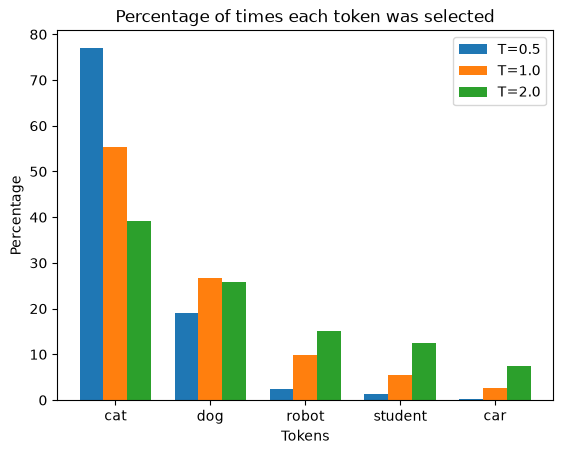

In [13]:

import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# CSE 368 Homework
# Greedy Decoding, Random Sampling, Temperature
# Remember there are no separate reports for this homework so use the
# capabilities of colab or other notebooks to explain y
# --------------------------------------------------

# Simulated output from a language model
tokens = ["cat", "dog", "robot", "student", "car"]

# These values are logits, NOT probabilities
logits = np.array([2.5, 1.8, 0.7, 0.2, -0.5])


# Task 1: Convert logits into probabilities
def softmax(logits):
    """
    Convert logits into probabilities.
    The probabilities should sum to approximately 1.
    Use a numerically stable implementation.
    """
    probabilities = []
    max_logit = np.max(logits)

    for i in range(len(logits)):
        i_probability = np.exp(logits[i] - max_logit) / np.sum(np.exp(logits - max_logit))
        probabilities.append(i_probability)
    return np.array(probabilities)

probabilities = softmax(logits)

for i in range(len(tokens)):
        print(f"{tokens[i]}: {probabilities[i]:.4f}")

# Task 2: Greedy decoding
def greedy_decode(tokens, logits):
    """
    Return the token with the highest logit.
    """
    probabilities = softmax(logits)
    return tokens[np.argmax(probabilities)]


# Task 3: Random sampling
def random_sampling(tokens, logits):
    """
    Sample a token according to softmax probabilities.
    Higher-probability tokens should be selected more often.
    """
    # TODO: Calculate probabilities using softmax()
    probabilities = softmax(logits)
    # TODO: Sample one token using np.random.choice()
    selected_token = np.random.choice(tokens, p = probabilities)
    return selected_token


# Task 4: Temperature-based sampling
def temperature_sampling(tokens, logits, temperature):
    """
    Divide logits by temperature, apply softmax,
    and sample one token from the resulting distribution.
    """
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero.")

    # TODO: Scale logits by temperature
    scaled_logits = logits / temperature
    # TODO: Calculate probabilities
    probabilities = softmax(scaled_logits)
    # TODO: Sample and return one token
    selected_token = np.random.choice(tokens, p=probabilities)
    return selected_token

for temperature in [0.5, 1.0, 2.0]:
    print(f"\nTemperature = {temperature} \nSelected Token = {temperature_sampling(tokens, logits, temperature)}")

# Task 5: Compare Experiments 
np.random.seed(42)
num_of_trials = 1000
# Experiment 1: Greedy Decoding
greedy_count = {"cat": 0, "dog": 0, "robot": 0, "student": 0, "car": 0}
for i in range(num_of_trials):
    token = greedy_decode(tokens, logits)
    greedy_count[token] += 1

# Experiment 2: Random Sampling
random_count = {"cat": 0, "dog": 0, "robot": 0, "student": 0, "car": 0}
for i in range(num_of_trials):
    token = random_sampling(tokens, logits)
    random_count[token] += 1

# Experiment 3: Temperature Sampling thousand per temperature 
temp05_count = {"cat": 0, "dog": 0, "robot": 0, "student": 0, "car": 0}
for i in range(num_of_trials):
    token = temperature_sampling(tokens, logits, 0.5)
    temp05_count[token] += 1

temp1_count = {"cat": 0, "dog": 0, "robot": 0, "student": 0, "car": 0}
for i in range(num_of_trials):
    token = temperature_sampling(tokens, logits, 1.0)
    temp1_count[token] += 1

temp2_count = {"cat": 0, "dog": 0, "robot": 0, "student": 0, "car": 0}
for i in range(num_of_trials):
    token = temperature_sampling(tokens, logits, 2.0)
    temp2_count[token] += 1

# Table number
print("\nNumber of times each token was selected:")
print(f"{'Token':<10}{'Greedy':<10}{'Random':<10}{'T=0.5':<10}{'T=1.0':<10}{'T=2.0':<10}")
for t in tokens:
    print(f"{t:<10}{greedy_count[t]:<10}{random_count[t]:<10}{temp05_count[t]:<10}{temp1_count[t]:<10}{temp2_count[t]:<10}")

# Percentage table 
print("\nPercentage of times each token was selected:")
print(f"{'Token':<10}{'Greedy':<10}{'Random':<10}{'T=0.5':<10}{'T=1.0':<10}{'T=2.0':<10}")
for t in tokens:
    greedy_percentage = greedy_count[t] / num_of_trials * 100
    random_percentage = random_count[t] / num_of_trials * 100
    temp05_percentage = temp05_count[t] / num_of_trials * 100
    temp1_percentage = temp1_count[t] / num_of_trials * 100
    temp2_percentage = temp2_count[t] / num_of_trials * 100
    print(f"{t:<10}{greedy_percentage:<10.2f}{random_percentage:<10.2f}{temp05_percentage:<10.2f}{temp1_percentage:<10.2f}{temp2_percentage:<10.2f}")

# bar chat
temp05_percentage = []
temp1_percentage = []
temp2_percentage = []
for t in tokens:
    temp05_percentage.append(temp05_count[t] / num_of_trials * 100)
    temp1_percentage.append(temp1_count[t] / num_of_trials * 100)
    temp2_percentage.append(temp2_count[t] / num_of_trials * 100)

x = np.arange(len(tokens))
plt.bar(x - 0.25, temp05_percentage, width=0.25, label='T=0.5')
plt.bar(x, temp1_percentage, width=0.25, label='T=1.0')
plt.bar(x + 0.25, temp2_percentage, width=0.25, label='T=2.0')
plt.xticks(x, tokens)
plt.xlabel('Tokens')
plt.ylabel('Percentage')
plt.title('Percentage of times each token was selected')
plt.legend()
plt.show()





# Task 6: Analyze the results
1. Which token is selected by greedy decoding, and why?
    - The cat token is selected because greedy always selects the token with the kighest logit so in all 1000 run it selected cat which has a value of 2.5.
2. Why is random sampling different from uniformly selecting a random token?
    - Random sampling uses the softmax probabilites, cat has a a softmax of 55.19% ans was chozen 55.9% of the time unlike uniformly selecting random tokens which would have selected cat 20% of the time. 
3. How does lowering the temperature affect the probability distribution?
    - A lower lemperature makes the dirstibution concentrate on the higest scroing token. The gap between cat and car on selection percantage increases with a lower temperature. (view the bar graph)
4. Why might a language model use sampling instead of greedy decoding?
    - Greedy decoding always gives the same output for the same input while sampling adds variety in answers, alowing a model to sound more human and have creative responses. 
5. What are two advantages and two disadvantages of using a higher temperature for text generation?
    Advantages:
     - more varitey/creativity
     - less likley to repeat output
    Disadvantages:
     - less predictable
     - less accurate